# COU 07506 Digital Signal Processing — Week 02: Sampling, Aliasing and Quantization


**Name:** BARAKA MARTIN MDEKA
**Registration Number:** 240242436939
**Date:** 25/11/2026



In [10]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab

**(a)** A 7 kHz tone is sampled at 10 kHz. The Nyquist frequency is $f_s/2 = 5$ kHz, and $7 > 5$ kHz, so the tone aliases:

$$F_{alias} = |F - k f_s| = |7 - 10| = 3 \text{ kHz}$$

**(b)** For $B = 8$ bits and $X_m = 1$ V:

$$\Delta = \frac{2X_m}{2^B} = \frac{2}{256} = 0.0078125 \text{ V} = 7.8125 \text{ mV}$$

$$\text{SQNR} \approx 6.02B + 1.76 = 6.02(8) + 1.76 = 49.92 \text{ dB}$$

Error variance: $\sigma_e^2 = \Delta^2/12 \approx 5.09\times10^{-6}\ \text{V}^2$.

In [11]:
# Quick numerical check of the pre-lab numbers
B, Xm = 8, 1.0
delta = 2*Xm / 2**B
print(f"Delta = {delta*1e3:.4f} mV")
print(f"SQNR  = {6.02*B + 1.76:.2f} dB")
print(f"Error variance = {delta**2/12:.3e} V^2")
print("alias of 7 kHz at fs = 10 kHz:", abs(7 - 10*round(7/10)), "kHz")

Delta = 7.8125 mV
SQNR  = 49.92 dB
Error variance = 5.086e-06 V^2
alias of 7 kHz at fs = 10 kHz: 3 kHz


## Task 2.1 — Aliasing of a sinusoid

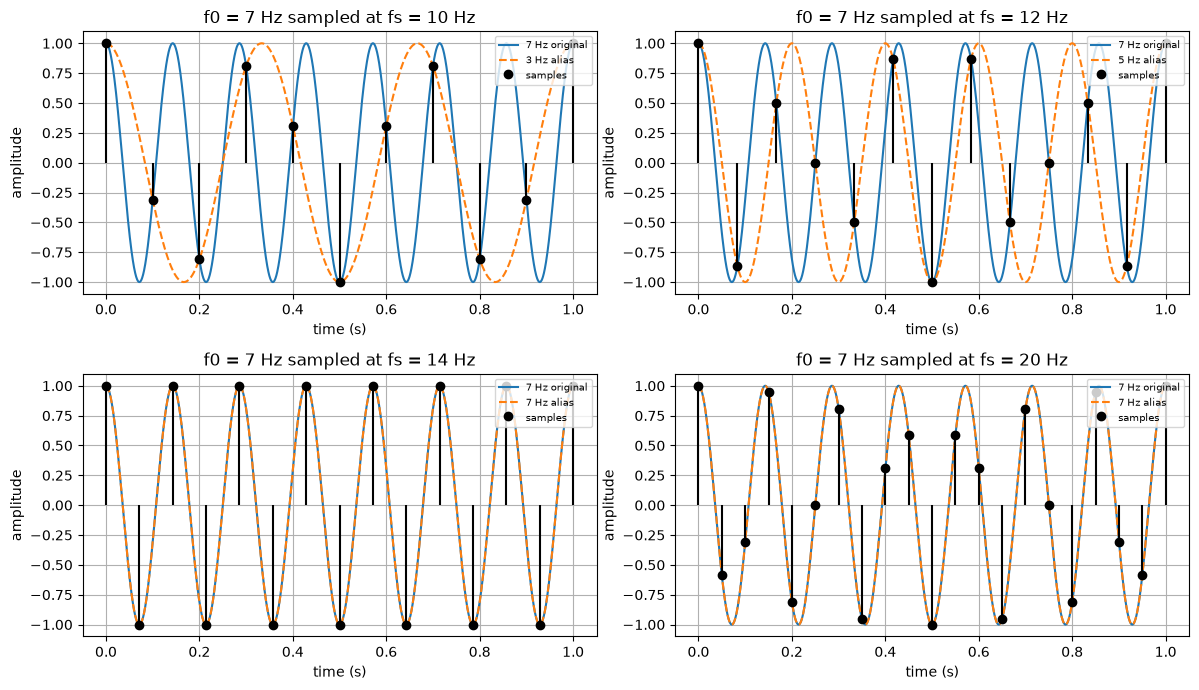

 fs (Hz)   f0/fs   k   |f0 - k*fs| (Hz)
      10   0.700   1                  3
      12   0.583   1                  5
      14   0.500   0                  7
      20   0.350   0                  7


In [12]:
f0 = 7.0
fs_list = [10.0, 12.0, 14.0, 20.0]
table = []

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, fs_ in zip(axes.ravel(), fs_list):
    t = np.linspace(0, 1, 2000)              # dense grid = "analog" signal
    n = np.arange(0, int(fs_) + 1)
    tn = n / fs_
    k = round(f0 / fs_)
    f_alias = abs(f0 - fs_*k)
    table.append((fs_, f0/fs_, k, f_alias))

    ax.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0:g} Hz original")
    ax.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias:g} Hz alias")
    ax.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ", label="samples")
    ax.set_title(f"f0 = {f0:g} Hz sampled at fs = {fs_:g} Hz")
    ax.set_xlabel("time (s)"); ax.set_ylabel("amplitude")
    ax.legend(loc="upper right", fontsize=7); ax.grid(True)
plt.tight_layout(); plt.show()

print(f"{'fs (Hz)':>8} {'f0/fs':>7} {'k':>3} {'|f0 - k*fs| (Hz)':>18}")
for fs_, r, k, fa in table:
    print(f"{fs_:8g} {r:7.3f} {k:3d} {fa:18g}")

**Alias table and observation**

| $f_s$ (Hz) | $f_0/f_s$ | nearest $k$ | alias $|7 - kf_s|$ (Hz) | comment |
|---|---|---|---|---|
| 10 | 0.700 | 1 | 3 | aliased |
| 12 | 0.583 | 1 | 5 | aliased |
| 14 | 0.500 | 0 | 7 | tone sits exactly at the Nyquist frequency (worst case, borderline) |
| 20 | 0.350 | 0 | 7 | no aliasing ($7 < 10$ Hz) |

The simulated alias frequency matches $|F - kf_s|$ in every case. In the plots, the samples of the 7 Hz tone fall exactly on the dashed alias curve for $f_s = 10$ and $12$ Hz.

## Task 2.2 — Hear aliasing

In [13]:
fname = "Audio.wav"          # your Week 1 recording

if os.path.exists(fname):
    fs_v, x_v = wavfile.read(fname)
    x_v = x_v.astype(float)
    if x_v.ndim > 1:            # stereo -> mono
        x_v = x_v.mean(axis=1)
    x_v = x_v / np.max(np.abs(x_v))
    print("Using Audio.wav")
else:                           # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs_v = 44100
    t_v = np.arange(0, 3, 1/fs_v)
    x_v = 0.5*signal.chirp(t_v, 200, 3, 15000)
    print("Audio.wav not found: using the fallback chirp")

print(f"fs = {fs_v} Hz, duration = {len(x_v)/fs_v:.2f} s, samples = {len(x_v)}")

for k in [2, 4, 8]:
    naive  = x_v[::k]                              # no filter -> aliasing
    proper = signal.decimate(x_v, k, ftype="fir")  # low-pass, then drop
    print(f"\nk = {k}, new fs = {fs_v//k} Hz")
    print("naive (aliased):");       display(Audio(naive,  rate=fs_v//k))
    print("proper (FIR anti-alias):"); display(Audio(proper, rate=fs_v//k))

Using Audio.wav
fs = 48000 Hz, duration = 4.22 s, samples = 202752

k = 2, new fs = 24000 Hz
naive (aliased):


proper (FIR anti-alias):



k = 4, new fs = 12000 Hz
naive (aliased):


proper (FIR anti-alias):



k = 8, new fs = 6000 Hz
naive (aliased):


proper (FIR anti-alias):


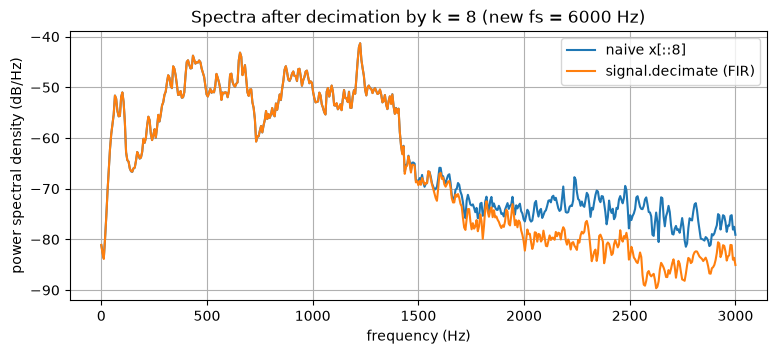

In [14]:
# Spectra for k = 8: the naive version shows energy folded back into the band
k = 8
naive  = x_v[::k]
proper = signal.decimate(x_v, k, ftype="fir")
f1, P1 = signal.welch(naive,  fs=fs_v//k, nperseg=1024)
f2, P2 = signal.welch(proper, fs=fs_v//k, nperseg=1024)
plt.figure()
plt.plot(f1, 10*np.log10(P1 + 1e-20), label="naive x[::8]")
plt.plot(f2, 10*np.log10(P2 + 1e-20), label="signal.decimate (FIR)")
plt.xlabel("frequency (Hz)"); plt.ylabel("power spectral density (dB/Hz)")
plt.title(f"Spectra after decimation by k = {k} (new fs = {fs_v//k} Hz)")
plt.legend(); plt.grid(True); plt.show()

**Listening observation ($k = 8$)** — *edit this after you listen with headphones:*

- **Naive version:** harsh and "metallic"/robotic. Content above the new Nyquist frequency ($f_s/16$) folded back into the audible band and mixes with the real low frequencies.
- **Proper version:** cleaner but more muffled. The FIR low-pass filter removed everything above the new Nyquist frequency before samples were dropped, so nothing could fold back.

The spectrum plot above shows the same thing: the naive curve has extra energy across the band that the filtered curve does not.

## Task 2.3 — A uniform quantizer

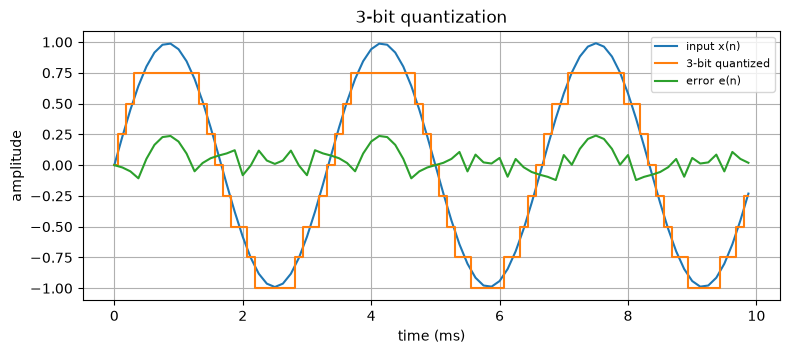

Delta = 0.25, Delta/2 = 0.125
max |error| overall          = 0.240
max |error| where not clipped = 0.121


In [15]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs_s = 8000
t_s = np.arange(0, 0.01, 1/fs_s)
x_s = 0.99*np.sin(2*np.pi*300*t_s)     # test sine (kept separate from the voice signal)

xq = quantize(x_s, 3)

plt.figure()
plt.plot(t_s*1e3, x_s, label="input x(n)")
plt.step(t_s*1e3, xq, where="mid", label="3-bit quantized")
plt.plot(t_s*1e3, x_s - xq, label="error e(n)")
plt.xlabel("time (ms)"); plt.ylabel("amplitude")
plt.title("3-bit quantization")
plt.legend(loc="upper right", fontsize=8); plt.grid(True); plt.show()

delta3 = 2/2**3
print(f"Delta = {delta3}, Delta/2 = {delta3/2}")
print(f"max |error| overall          = {np.max(np.abs(x_s - xq)):.3f}")
inside = np.abs(x_s) < (1 - delta3)
print(f"max |error| where not clipped = {np.max(np.abs(x_s - xq)[inside]):.3f}")

**Observation.** The 3-bit quantizer has $2^3 = 8$ levels with $\Delta = 2/8 = 0.25$, giving a staircase approximation. Away from the peaks the error stays within $\pm\Delta/2 = \pm 0.125$ (sawtooth-like). Near the peaks the error is larger (about 0.24) because the top level of this quantizer is $1 - \Delta = 0.75$, so values above about 0.875 are **clipped** rather than rounded. The $\pm\Delta/2$ bound only holds for the non-clipped samples.

## Task 2.4 — Verify the 6 dB-per-bit rule

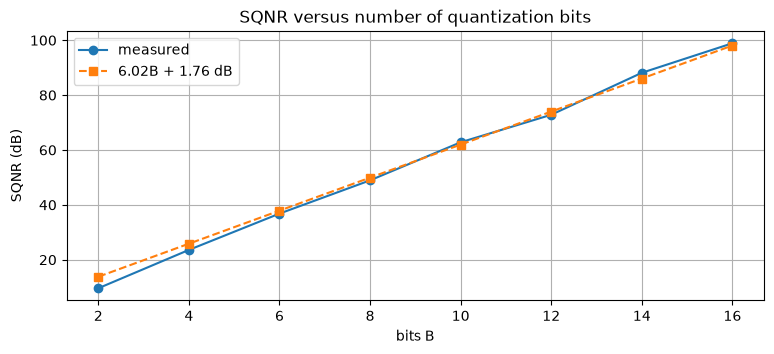

  B  measured (dB)  theory (dB)  diff (dB)
  2           9.60        13.80      -4.20
  4          23.58        25.84      -2.26
  6          36.81        37.88      -1.07
  8          48.93        49.92      -0.99
 10          62.81        61.96       0.85
 12          72.84        74.00      -1.16
 14          88.13        86.04       2.09
 16          98.91        98.08       0.83

slope of measured SQNR: [6.99 6.62 6.06 6.94 5.01 7.65 5.39] dB per bit


In [16]:
bits = np.arange(2, 17, 2)
meas = np.array([10*np.log10(np.sum(x_s**2)/np.sum((x_s - quantize(x_s, B))**2)) for B in bits])
theory = 6.02*bits + 1.76

plt.figure()
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, theory, "s--", label="6.02B + 1.76 dB")
plt.xlabel("bits B"); plt.ylabel("SQNR (dB)")
plt.title("SQNR versus number of quantization bits")
plt.legend(); plt.grid(True); plt.show()

print(f"{'B':>3} {'measured (dB)':>14} {'theory (dB)':>12} {'diff (dB)':>10}")
for B, m, th in zip(bits, meas, theory):
    print(f"{B:3d} {m:14.2f} {th:12.2f} {m-th:10.2f}")
print("\nslope of measured SQNR:", np.round(np.diff(meas)/np.diff(bits), 2), "dB per bit")

**Observation.** *Write your own reading of the table and graph here.* What to check: the measured slope should be close to 6 dB per bit (about 12 dB per 2-bit step), and the measured curve should run roughly parallel to the theory line. The offset from the theory line, especially at small $B$, comes from two things: the test sine has amplitude 0.99 rather than exactly full scale, and at low $B$ the top-level clipping from Task 2.3 adds error. The record is also only 3 cycles (80 samples), so the measured values are a little noisy.

## Task 2.5 — Quantize your voice

In [17]:
def sqnr_db(x, xq):
    return 10*np.log10(np.sum(x**2)/np.sum((x - xq)**2))

for B in [4, 8, 12]:
    xq_v = quantize(x_v, B)
    print(f"{B:2d}-bit: SQNR = {sqnr_db(x_v, xq_v):6.2f} dB   (full-scale sine theory: {6.02*B + 1.76:6.2f} dB)")
    display(Audio(xq_v, rate=fs_v))

crest_v = np.max(np.abs(x_v))/np.sqrt(np.mean(x_v**2))
print(f"\ncrest factor of recording = {crest_v:.2f}   (full-scale sine = {np.sqrt(2):.2f})")

 4-bit: SQNR =  10.44 dB   (full-scale sine theory:  25.84 dB)


 8-bit: SQNR =  34.46 dB   (full-scale sine theory:  49.92 dB)


12-bit: SQNR =  58.53 dB   (full-scale sine theory:  74.00 dB)



crest factor of recording = 8.40   (full-scale sine = 1.41)


**Why is the SQNR of speech lower than for a full-scale sine with the same number of bits?**
The step size $\Delta$ is fixed by the quantizer range (set by the peaks), so the noise power $\Delta^2/12$ is the same for every sample. A full-scale sine uses the whole range all the time, so its average power is as large as it can be. Speech has a high crest factor (peaks much larger than the RMS value) and long quiet passages, so its average power is far below the full-scale value while the noise power stays the same. The ratio, i.e. the SQNR, is therefore lower, and it is worst in the quiet parts. (If you are running on the fallback chirp instead of your voice, its lower SQNR comes from its amplitude of only 0.5, about 6 dB below full scale.)

## Analysis questions

**1. Why does the 7 Hz tone appear at 3 Hz when $f_s = 10$ Hz?** The sketch below shows the folding.

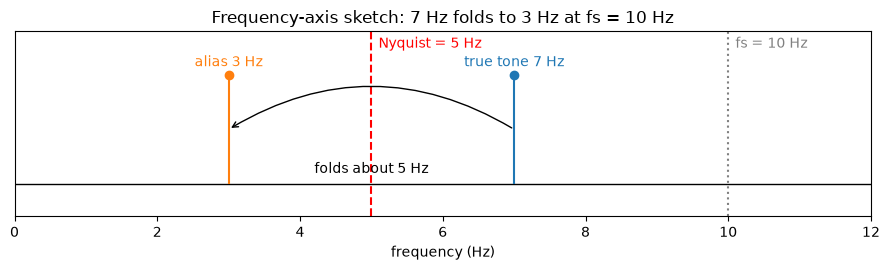

In [18]:
fs_, f0 = 10, 7
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.axhline(0, color="k", lw=1)
ax.set_xlim(0, 12); ax.set_ylim(-0.3, 1.4)
ax.axvline(fs_/2, color="r", ls="--"); ax.text(fs_/2 + 0.1, 1.25, "Nyquist = 5 Hz", color="r")
ax.axvline(fs_, color="gray", ls=":"); ax.text(fs_ + 0.1, 1.25, "fs = 10 Hz", color="gray")
ax.stem([f0], [1], linefmt="C0-", markerfmt="C0o", basefmt=" ")
ax.text(f0, 1.08, "true tone 7 Hz", ha="center", color="C0")
ax.stem([fs_ - f0], [1], linefmt="C1-", markerfmt="C1o", basefmt=" ")
ax.text(fs_ - f0, 1.08, "alias 3 Hz", ha="center", color="C1")
ax.annotate("", xy=(3, 0.5), xytext=(7, 0.5), arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.3"))
ax.text(5, 0.1, "folds about 5 Hz", ha="center")
ax.set_xlabel("frequency (Hz)"); ax.set_yticks([]); ax.set_title("Frequency-axis sketch: 7 Hz folds to 3 Hz at fs = 10 Hz")
plt.tight_layout(); plt.show()

Sampling at $f_s = 10$ Hz can represent frequencies only up to $f_s/2 = 5$ Hz. A component at 7 Hz lies above this limit and folds about 5 Hz: $5 - (7-5) = 3$ Hz, equivalently $|7 - 10| = 3$ Hz. Samples of $\cos(2\pi\cdot 7\,n/10)$ are identical to samples of $\cos(2\pi\cdot 3\,n/10)$, so the sampled sequence looks like a 3 Hz cosine.

**2. Why can the aliasing heard in the naïve version not be removed afterwards?** After folding, the alias sits at the same frequencies as genuine low-frequency content, and the samples of the two are numerically identical. No later filter can tell which part came from where, so the information is lost. Aliasing has to be prevented *before* sampling or downsampling, with an anti-aliasing low-pass filter.

**3. By how much does the SQNR change per added bit? Does the measurement agree?** One extra bit halves $\Delta$, so the noise power falls by a factor of 4, i.e. $10\log_{10}4 \approx 6.02$ dB. The measured slope printed in Task 2.4 should be close to this, with small deviations for the reasons given in the Task 2.4 observation.

**4. Temperature sensor (0–100 °C, 0.01 °C resolution, max 0.1 °C/s).**

- *Bits:* $100/0.01 = 10\,000$ levels are needed, and $2^{13} = 8192 < 10\,000 \le 2^{14} = 16\,384$, so $B = 14$ bits. Then $\Delta = 100/16384 \approx 0.0061$ °C, which meets the 0.01 °C requirement.
- *Sampling rate:* at the fastest change of 0.1 °C/s the reading moves by one resolution step (0.01 °C) every 0.1 s, so $f_s \approx 10$ Hz tracks every step. Because the sensor is slow its bandwidth is very small, so Nyquist is easily satisfied; 10 Hz is a comfortable choice, and a lower rate of a few Hz would also be enough if every single 0.01 °C step need not be captured. An analog low-pass filter before the ADC still protects against noise and interference aliasing.

## AI-use statement

**AI tools used:** DeepSeek and Claude
**Used for:**  formatting the notebook, explaining an error in Task 2.5
**How I verified the output:**  compared the alias table with $|F - kf_s|$; checked the Task 2.4 slope against 6 dB per bit; ran Restart and Run All
I confirm that I understand and can explain all submitted code.